**W9D2 Participation 10/21/26**

In [ ]:
#i was very confused on how to add a widget and dashboard

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display

results = pd.read_csv("chatgpt_detection_results.csv")
results.head()
results.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   submission_id          5000 non-null   str    
 1   tool                   5000 non-null   str    
 2   actual_type            5000 non-null   str    
 3   detected_as_ai         5000 non-null   bool   
 4   confidence_score       5000 non-null   float64
 5   text_length            5000 non-null   int64  
 6   subject                5000 non-null   str    
 7   grade_level            5000 non-null   str    
 8   writing_style_score    5000 non-null   float64
 9   perplexity_score       5000 non-null   float64
 10  detection_probability  5000 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(5)
memory usage: 584.6 KB


In [2]:
results.head()

,submission_id,tool,actual_type,detected_as_ai,confidence_score,text_length,subject,grade_level,writing_style_score,perplexity_score,detection_probability
0,SUB0000,Copyleaks,ai_generated,False,0.230527,4354,HIST,Graduate,0.371146,0.381355,0.653511
1,SUB0001,Copyleaks,human_written,False,0.643546,1056,PSYCH,Graduate,0.528367,0.248499,0.010329
2,SUB0002,Originality.ai,human_written,False,0.619367,2145,PSYCH,Freshman,0.254359,0.311960,0.009575
3,SUB0003,Copyleaks,human_written,False,0.570965,1579,MATH,Freshman,0.575367,0.263869,0.018074
4,SUB0004,GPTZero,human_written,False,0.335957,3153,BIO,Graduate,0.310787,0.350734,0.121960


In [4]:
results.shape

(5000, 11)

**Question 1: Are students pursuing advanced coursework, such as PhD and graduate programs, more likely to use AI?**

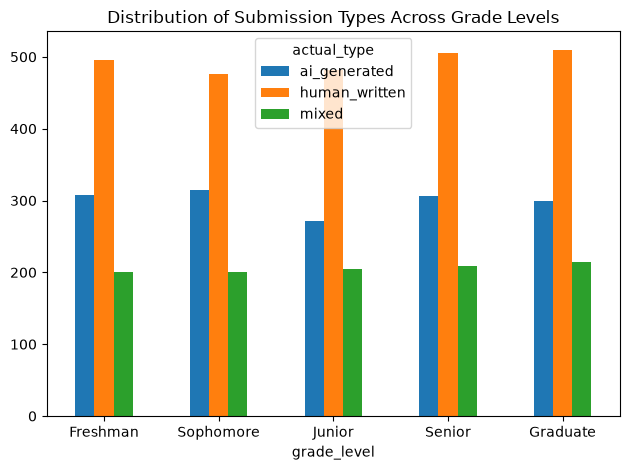

In [6]:
grade_order = ['Freshman','Sophomore','Junior','Senior','Graduate']

(
    results
    .groupby('grade_level')['actual_type']
    .value_counts()
    .unstack()
    .loc[grade_order]
    .plot.bar(rot=0)
)
plt.title("Distribution of Submission Types Across Grade Levels")
plt.tight_layout()
plt.show()

In [13]:
@interact(ascending=False)
def plot_submissions(ascending=False):
    results['grade_level'].value_counts().sort_values(ascending=ascending).plot.barh()
    plt.xlabel('grade level')
    plt.show()

interactive(children=(Checkbox(value=False, description='ascending'), Output()), _dom_classes=('widget-interac…

The visualization reveals that AI detection tools more commonly detect false negative errors than false positive errors. The heatmap displays darker colors in the false negative section, which indicates a higher frequency and count in that these AI detection tools are more prone to missing AI-generated text than incorrectly flagging human writing.

 Based on my visualization, different academic subjects experience higher average AI detection probabilities, as there are minor variations across academic subjects. In particular, English exhibits a higher median detection probability compared to the other subjects of the writing submissions. I notice subjects that have a greater emphasis on formulaic writing, especially computer science and chemistry, have a lower Q1 and median detection probability. The contrast in these descriptive statistics amongst different subjects suggest that AI detectors flag the narrative, freeform writing found in English more frequently than in subjects requiring more technical writing.

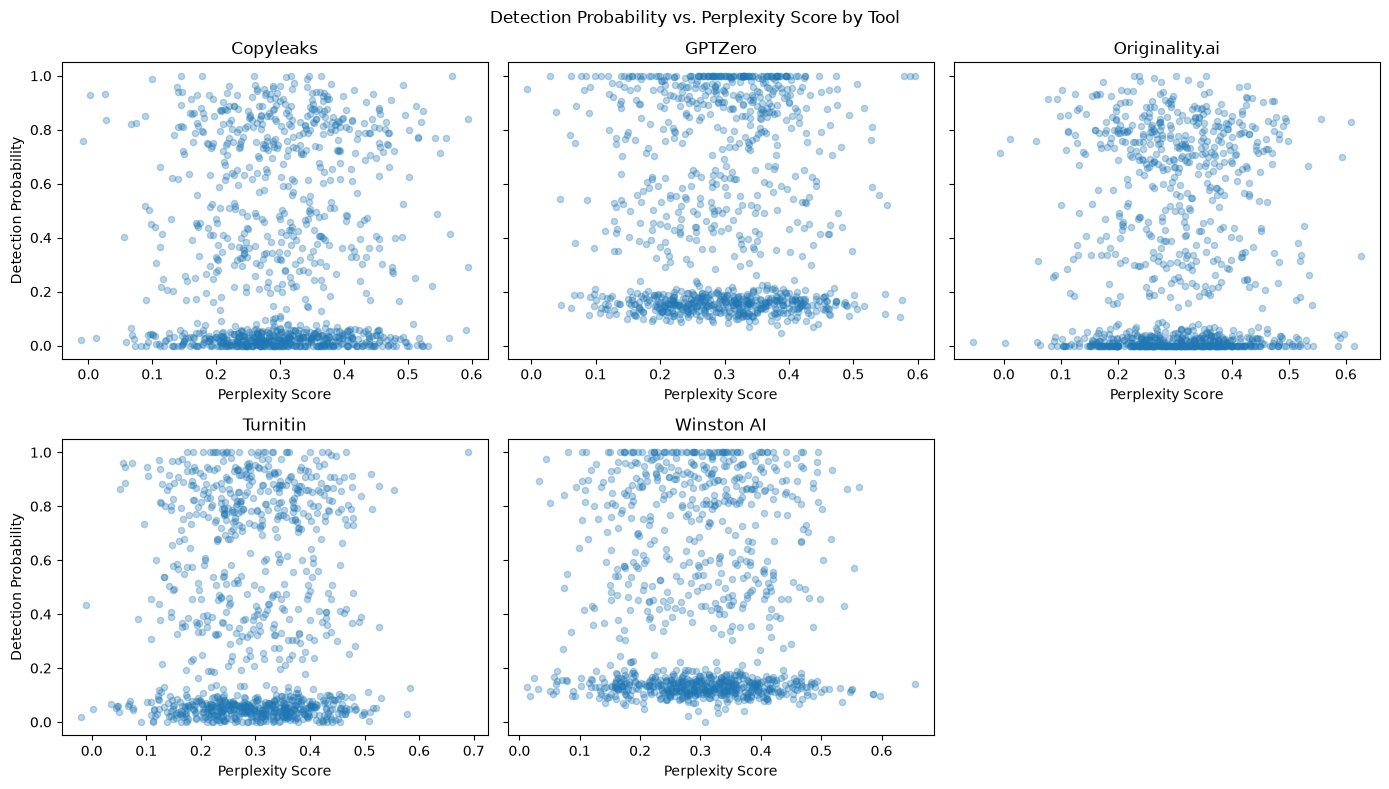

The perplexity score alone does not have a linear relationship with AI detection probability across the five tools, indicating that perplexity score does not influence a tool's detection probability. Based on the scatter subplots, there is heavy clustering near 0.0 and 1.0 with a perplexity range of 0.2 to 0.4. These results indicate that the AI detection tools rely on factors beyond text predictability to detect AI-generated text.

**Conclusion**

After exploring my initial research questions and additional exploratory analysis, I was surprise by my findings regarding how AI detection tools evaluate student writing.

The most surprising finding I had was that AI submission and detection trends remained surprisingly uniform across academic grade levels, from freshman to graduate students. Through my visualizations, it seems that the use or flagging of AI-generated work is not isolated to any singlular demographic. 

Additionally, I found that factors such as text length and perplexity have virtually no relationship with whether a text is flagged as AI-generated or human-written. My analysis also revealed that certain AI detection tools exhibit different rates of error type. For example, tools like Originality.ai showed the highest rates of false negative errors among the five tools, which falsely brush over AI in human-written text. False negative errors occured more frequently than false positive errors among all five tools. 

All five AI tools have some extent of unreliability, and false positive rates (that conclude AI detection in human-written text) can carry riskier implications for students. Thus, the conclusions of AI detection tools should be treated with caution as probable indicators rather than definitive proof.